In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from tabulate import tabulate

In [3]:
data = pd.read_csv('building_mold_risk_5min_1year(2).csv')

In [4]:
# Display dataset overview
print("Dataset Overview:")
print(tabulate(data.head(), headers="keys", tablefmt="pretty"))

Dataset Overview:
+---+------------+---------------------+-------------------+--------------------+--------------------+--------------------+-----------+
|   |    Date    |      Timestamp      |     Humidity      |    Temperature     |  Light_Intensity   |      Pressure      | Mold_Risk |
+---+------------+---------------------+-------------------+--------------------+--------------------+--------------------+-----------+
| 0 | 2023-01-01 | 2023-01-01 00:00:00 | 52.24505695438245 | 14.570697475053723 | 6.8170151388436615 | 1007.7673625891098 |    Low    |
| 1 | 2023-01-01 | 2023-01-01 00:05:00 | 49.70752286685369 | 19.60825307021918  | 15.293581813641534 | 1011.3497840331516 |    Low    |
| 2 | 2023-01-01 | 2023-01-01 00:10:00 | 52.85847227892171 | 16.899815756209787 | 13.86096472274046  | 1008.2605678805758 |    Low    |
| 3 | 2023-01-01 | 2023-01-01 00:15:00 | 56.37173053558358 | 16.479007833684353 | 10.968900816142227 | 1010.2765405123536 |    Low    |
| 4 | 2023-01-01 | 2023-01-01 

In [5]:
print("\nDataset Info:")
print(data.info())


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210528 entries, 0 to 210527
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Date             210528 non-null  object 
 1   Timestamp        210528 non-null  object 
 2   Humidity         210528 non-null  float64
 3   Temperature      210528 non-null  float64
 4   Light_Intensity  210528 non-null  float64
 5   Pressure         210528 non-null  float64
 6   Mold_Risk        210528 non-null  object 
dtypes: float64(4), object(3)
memory usage: 11.2+ MB
None


In [6]:
# Display summary statistics
print("\nSummary Statistics:")
summary_stats = data.describe()
print(tabulate(summary_stats, headers="keys", tablefmt="pretty"))


Summary Statistics:
+-------+--------------------+--------------------+--------------------+--------------------+
|       |      Humidity      |    Temperature     |  Light_Intensity   |      Pressure      |
+-------+--------------------+--------------------+--------------------+--------------------+
| count |      210528.0      |      210528.0      |      210528.0      |      210528.0      |
| mean  | 60.006244819245175 | 21.998079871546018 | 283.8658200794276  | 1012.9922009773896 |
|  std  | 13.341342823330757 | 6.816911854574989  | 289.8862588760461  |  7.6445482043222   |
|  min  |        30.0        |        5.0         |        0.0         | 993.0397726312872  |
|  25%  | 50.09597304632773  | 17.115666069197786 | 10.352908198303501 | 1006.4352155306599 |
|  50%  | 60.00325221154627  |  21.9626875554737  | 237.47822295707812 | 1013.0109847440425 |
|  75%  | 69.89900856251816  | 26.90958280085176  | 542.9696479141505  | 1019.5428828602271 |
|  max  | 98.97502977912558  |        4

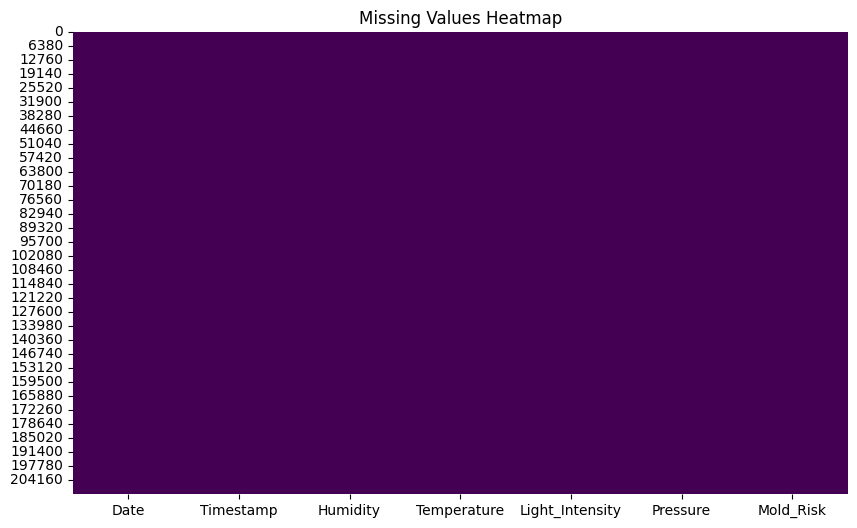

In [7]:
# Visualize missing values
plt.figure(figsize=(10, 6))
sns.heatmap(data.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

In [8]:
print("\nDuplicate Rows:", data.duplicated().sum())
data = data.drop_duplicates()


Duplicate Rows: 0


In [9]:
for col in data.select_dtypes(include=[np.number]).columns:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    data = data[(data[col] >= lower_bound) & (data[col] <= upper_bound)]

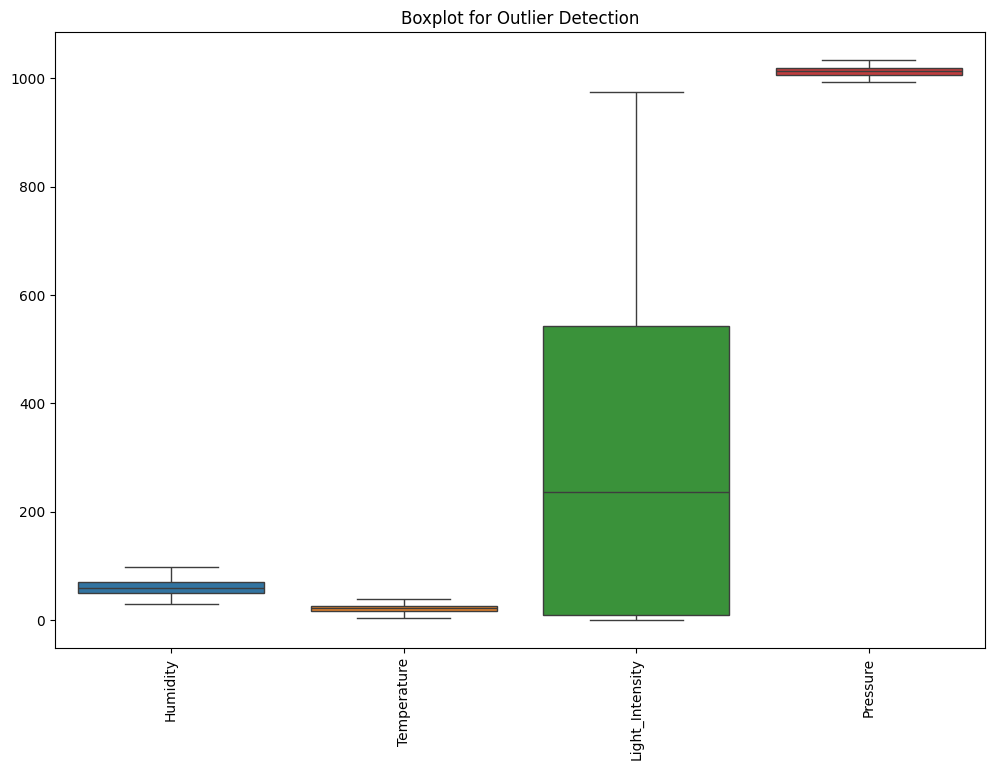

In [10]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=data)
plt.title("Boxplot for Outlier Detection")
plt.xticks(rotation=90)
plt.show()

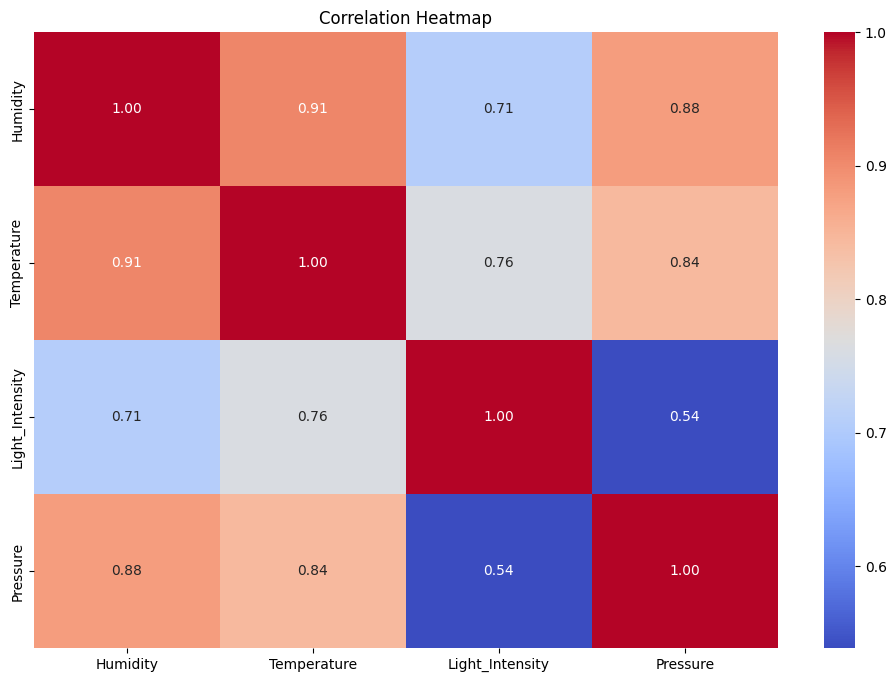

In [11]:
# Filter numeric columns
numeric_data = data.select_dtypes(include=[float, int])

# Check if there are enough numeric columns
if numeric_data.shape[1] >= 2:
    # Compute correlation and plot heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm', fmt=".2f")
    plt.title("Correlation Heatmap")
    plt.show()
else:
    print("Not enough numeric data for correlation heatmap.")

In [12]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [13]:
numeric_cols = data.select_dtypes(include=[np.number]).columns

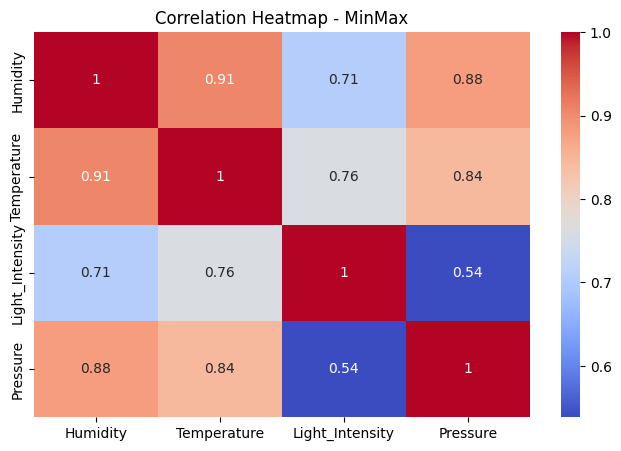

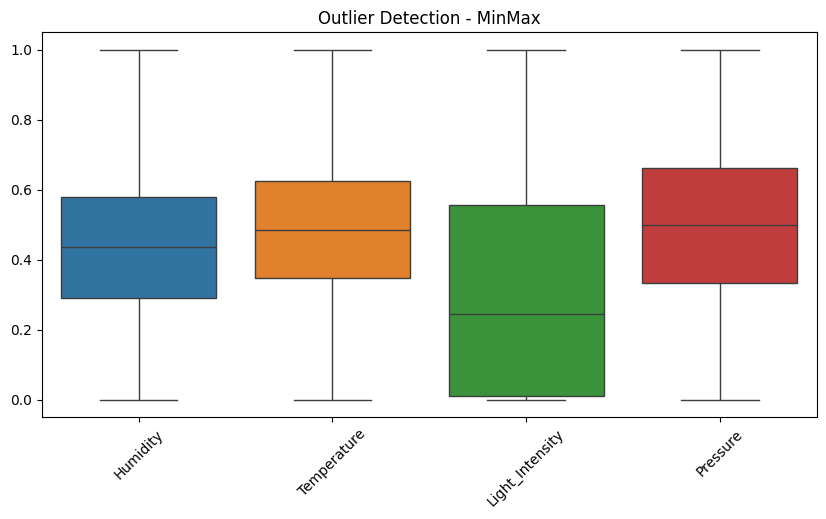

In [31]:
#MinMax Normalization
scaler = MinMaxScaler()
data_minmax = data.copy()
data_minmax[numeric_cols] = scaler.fit_transform(data[numeric_cols])

# Correlation Heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(data_minmax.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap - MinMax")
plt.show()

# Boxplot for Outlier Detection
plt.figure(figsize=(10, 5))
sns.boxplot(data=data_minmax)
plt.title("Outlier Detection - MinMax")
plt.xticks(rotation=45)
plt.show()

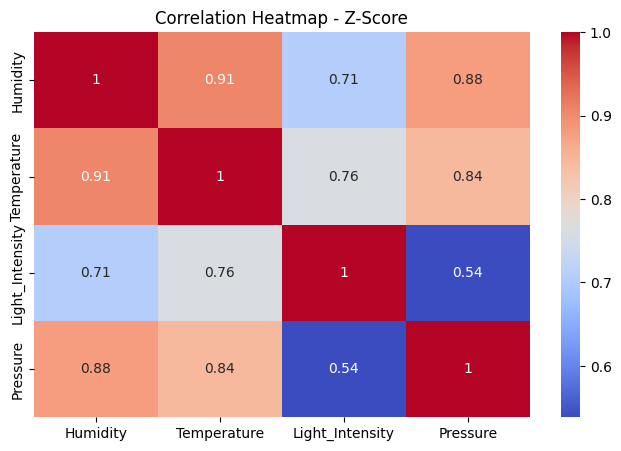

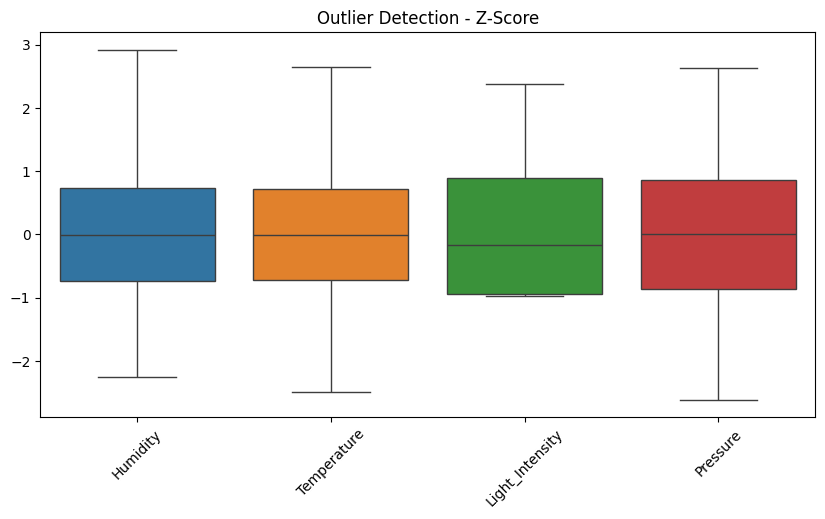

In [32]:
#Z-Score Normalization
scaler = StandardScaler()
data_standard = data.copy()
data_standard[numeric_cols] = scaler.fit_transform(data[numeric_cols])
# Correlation Heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(data_standard.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap - Z-Score")
plt.show()

# Boxplot for Outlier Detection
plt.figure(figsize=(10, 5))
sns.boxplot(data=data_standard)
plt.title("Outlier Detection - Z-Score")
plt.xticks(rotation=45)
plt.show()


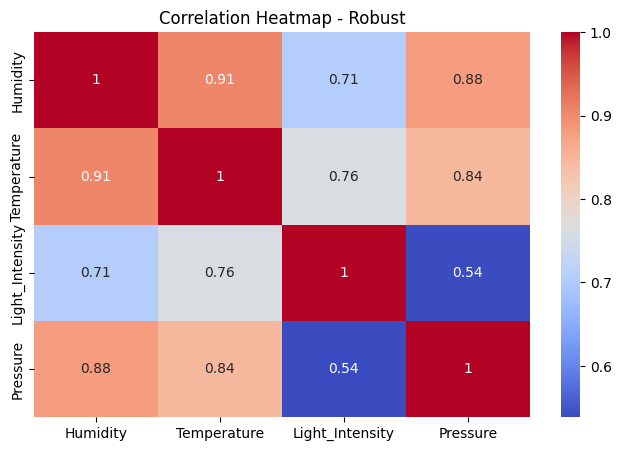

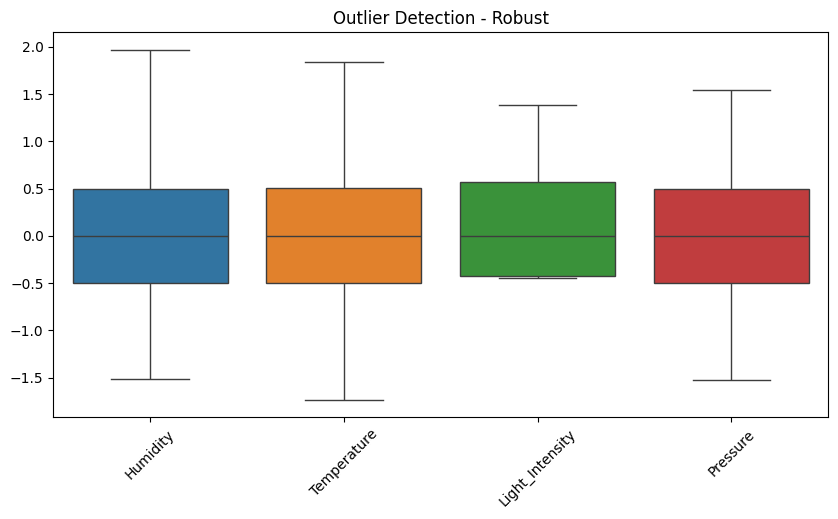

In [33]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
data_robust = data.copy()
data_robust[numeric_cols] = scaler.fit_transform(data[numeric_cols])

plt.figure(figsize=(8, 5))
sns.heatmap(data_robust.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap - Robust")
plt.show()

# Boxplot for Outlier Detection
plt.figure(figsize=(10, 5))
sns.boxplot(data=data_robust)
plt.title("Outlier Detection - Robust")
plt.xticks(rotation=45)
plt.show()

In [22]:
print("Original Data (first 5 rows):")
print(data[numeric_cols].head())

print("\nMin-Max Normalized Data:")
print(data_minmax[numeric_cols].head())

print("\nZ-Score Standardized Data:")
print(data_standard[numeric_cols].head())

print("\nRobust Scaled Data:")
print(data_robust[numeric_cols].head())


Original Data (first 5 rows):
    Humidity  Temperature  Light_Intensity     Pressure
0  52.245057    14.570697         6.817015  1007.767363
1  49.707523    19.608253        15.293582  1011.349784
2  52.858472    16.899816        13.860965  1008.260568
3  56.371731    16.479008        10.968901  1010.276541
4  49.359640    14.269151         9.284453  1010.289639

Min-Max Normalized Data:
   Humidity  Temperature  Light_Intensity  Pressure
0  0.322509     0.273448         0.006992  0.367205
1  0.285720     0.417379         0.015687  0.456527
2  0.331402     0.339995         0.014218  0.379503
3  0.382337     0.327972         0.011251  0.429767
4  0.280676     0.264833         0.009523  0.430094

Z-Score Standardized Data:
   Humidity  Temperature  Light_Intensity  Pressure
0 -0.581741    -1.089555        -0.955718 -0.683474
1 -0.771942    -0.350574        -0.926477 -0.214849
2 -0.535762    -0.747886        -0.931419 -0.618957
3 -0.272426    -0.809617        -0.941395 -0.355242
4 -0.798